# 02 - Modelling and evaluation
All numbers come from `reports/model_comparison.csv`, produced by `python -m ml.train`.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from ml.config import FIG_DIR, PROC_DIR, REPORT_DIR, MODEL_DIR
sns.set_theme(style='whitegrid')
def save(name): plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=130); plt.show()
df = pd.read_parquet(PROC_DIR / 'clean.parquet')
df['month'] = df.timestamp.dt.month; df['hour'] = df.timestamp.dt.hour; df['year'] = df.timestamp.dt.year
df['season'] = df.month.map(lambda m: 'Winter' if m in (11,12,1,2) else 'Monsoon' if m in (6,7,8,9) else 'Other')
comp = pd.read_csv(REPORT_DIR/'model_comparison.csv'); meta = pd.read_json(MODEL_DIR/'metadata.json', typ='series')
len(meta.features), meta.latest_data_timestamp

(73, '2026-10-05 22:00:00')

## Feature groups and why they help
| Group | Examples | Why |
|---|---|---|
| Lags | PM2.5 t-1 ... t-168 | Pollution is highly autocorrelated; the last day and week set the baseline |
| Rolling stats | mean/std/min/max over 6-168 h | Smooth noise, capture regime and volatility |
| Trend | diff 24 h, 6 h slope | Rising vs falling episodes |
| Weather | wind, humidity, rain, pressure, stagnation | Dispersion and wet removal |
| Calendar | hour, month, season, Diwali | Traffic cycles, winter inversion, fireworks |
| City | lat, lon | Local climate/emission level |
| Ratios | PM2.5/PM10, NO2/CO | Source mix (dust vs combustion) |

## Model comparison

In [2]:
for t in comp.test.unique():
    print(t); display(comp[comp.test==t].pivot_table(index='model', columns='horizon', values='RMSE').round(2))

A_recent90d


horizon,6,12,24,36,48,60,72
model,,,,,,,
LightGBM,9.71,11.39,12.80,14.78,15.67,16.55,16.91
LightGBM_log,9.71,11.45,13.00,15.11,15.99,16.78,17.39
Mean7d,16.43,16.88,17.72,18.46,19.02,19.47,19.78
Persistence,12.92,16.13,13.68,18.95,18.02,21.52,20.19
RandomForest,9.83,NaN,12.84,NaN,15.76,NaN,17.01
Ridge,10.09,NaN,12.90,NaN,16.00,NaN,17.21
SeasonalNaive,13.62,13.64,13.68,18.01,18.02,20.19,20.19
Stacking,9.69,NaN,13.03,NaN,16.04,NaN,17.46
XGBoost,9.95,NaN,12.74,NaN,15.68,NaN,16.87


B_winter


horizon,6,12,24,36,48,60,72
model,,,,,,,
LightGBM,15.65,19.57,22.03,25.45,26.32,27.73,27.30
LightGBM_log,16.70,20.54,22.75,26.94,27.55,29.63,29.65
Mean7d,30.64,31.15,31.99,32.61,33.03,33.32,33.48
Persistence,30.96,37.79,24.10,41.88,30.56,44.69,34.32
RandomForest,16.48,NaN,21.89,NaN,26.03,NaN,27.83
Ridge,17.89,NaN,21.92,NaN,25.98,NaN,27.77
SeasonalNaive,24.10,24.12,24.10,30.54,30.56,34.37,34.32
Stacking,16.08,NaN,22.18,NaN,26.75,NaN,29.19
XGBoost,16.86,NaN,21.94,NaN,25.76,NaN,27.45


In [3]:
summ = pd.read_csv(REPORT_DIR/'summary_best_models.csv'); display(summ.round(3))

,model,horizon,test,n_test,MAE,RMSE,R2,skill_vs_persistence,persistence_RMSE
0,LightGBM,6,A_recent90d,21600,5.746,9.711,0.826,0.248,12.922
1,LightGBM,12,A_recent90d,21600,6.796,11.391,0.762,0.294,16.132
2,XGBoost,24,A_recent90d,21600,7.470,12.743,0.704,0.069,13.683
3,LightGBM,36,A_recent90d,21600,8.745,14.785,0.606,0.220,18.946
4,XGBoost,48,A_recent90d,21600,9.174,15.676,0.560,0.130,18.023
5,LightGBM,60,A_recent90d,21600,9.859,16.545,0.515,0.231,21.518
6,LightGBM,72,A_recent90d,21600,9.948,16.915,0.496,0.162,20.193
7,LightGBM,6,B_winter,28800,10.660,15.654,0.874,0.494,30.959
8,LightGBM,12,B_winter,28800,13.321,19.565,0.803,0.482,37.794
9,XGBoost,24,B_winter,28800,15.050,21.942,0.753,0.090,24.099


## Figures

eval_actual_vs_pred_24h_A_recent90d.png


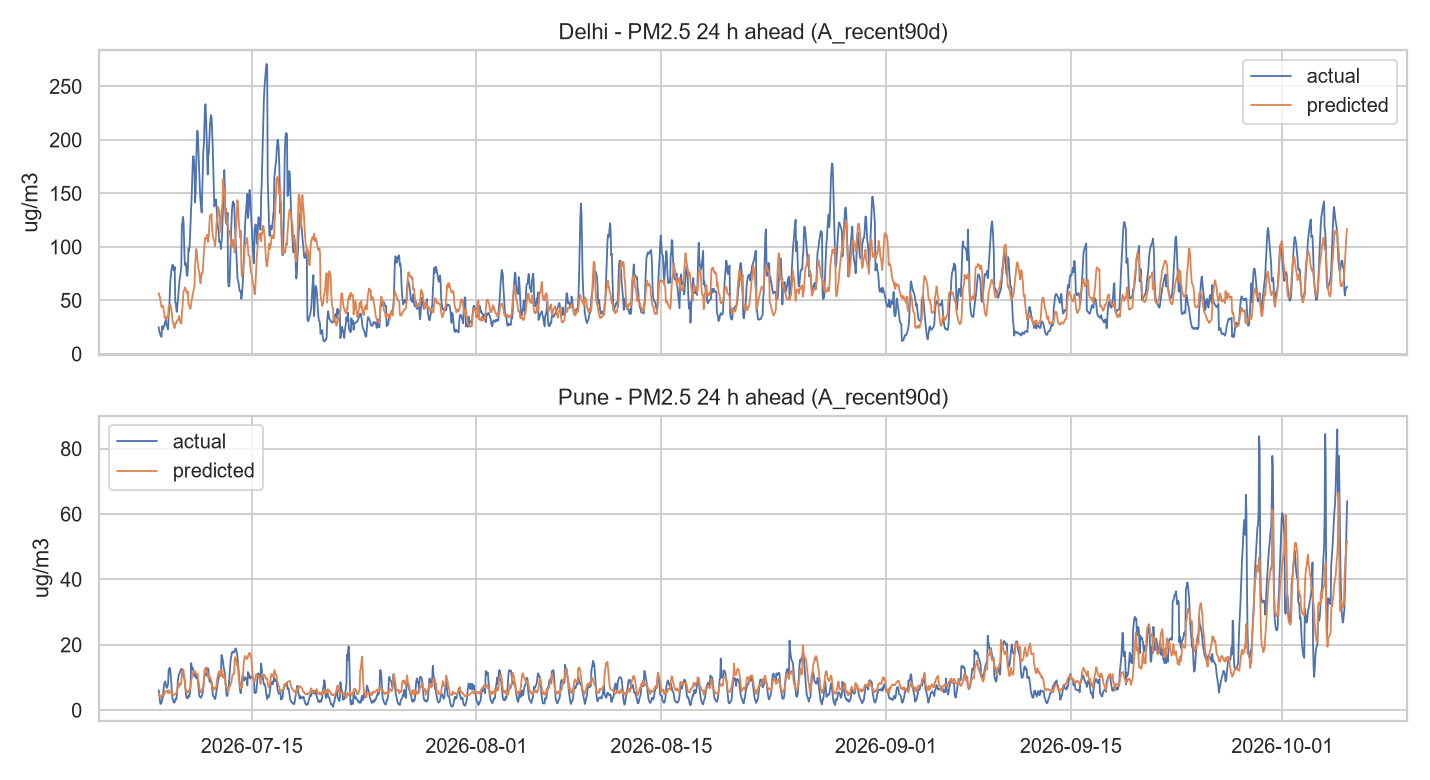

eval_actual_vs_pred_24h_B_winter.png


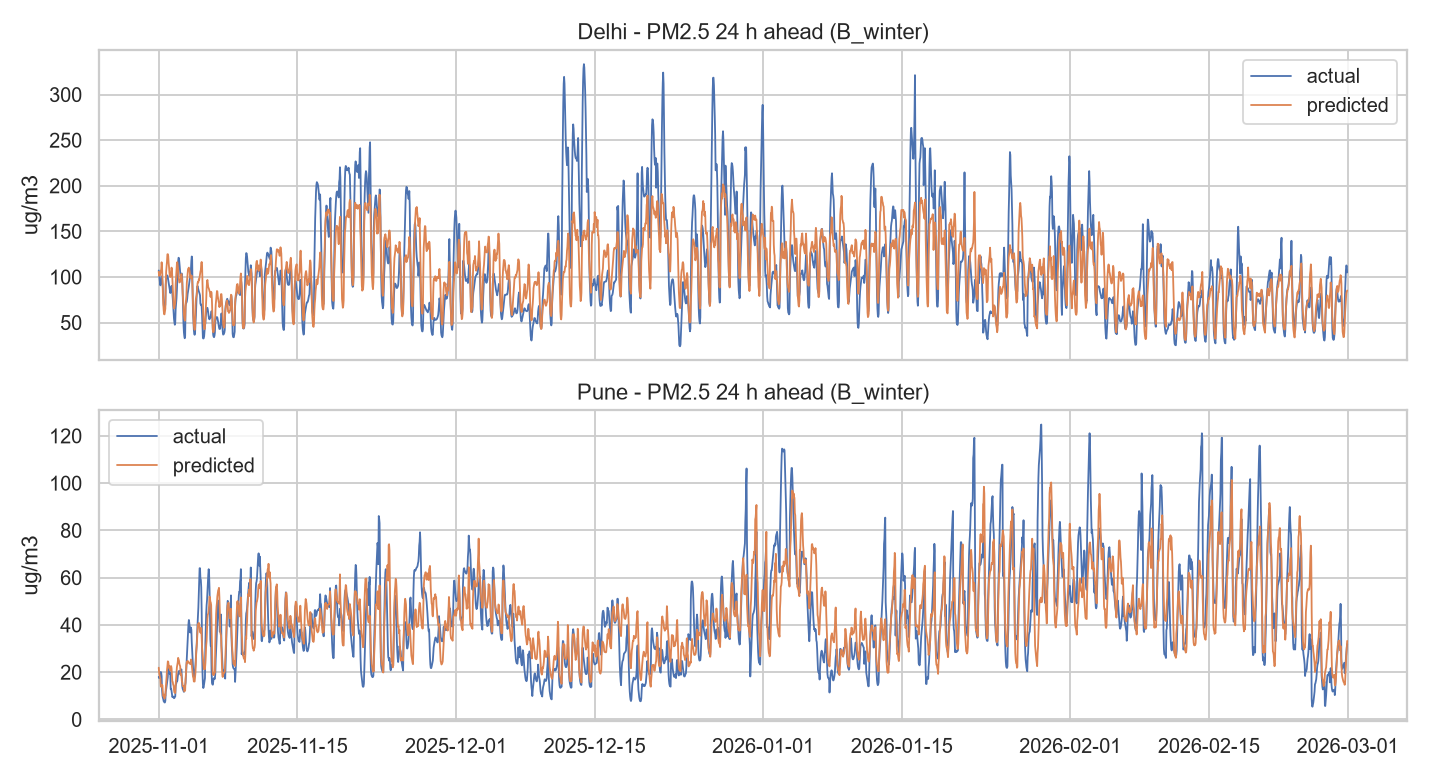

eval_actual_vs_pred_72h_A_recent90d.png


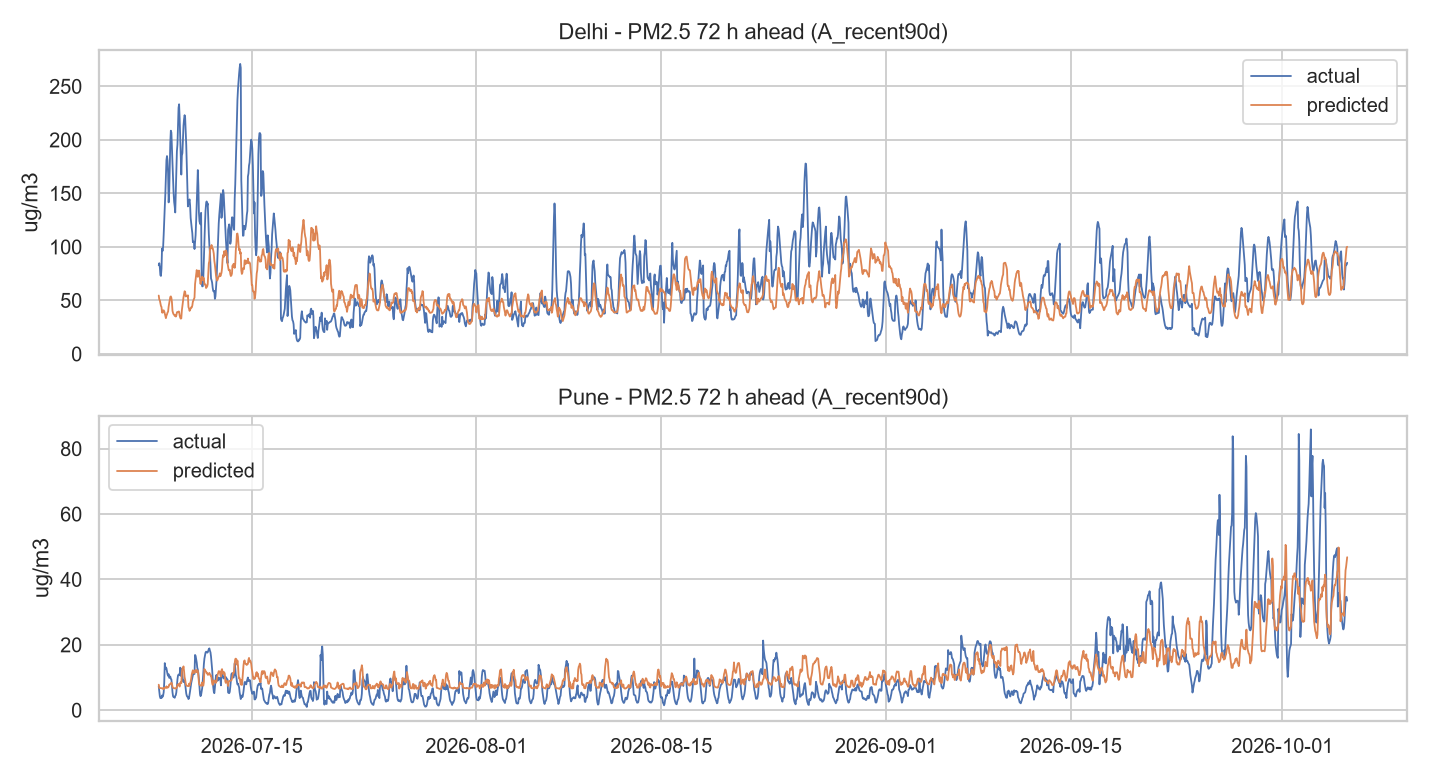

eval_actual_vs_pred_72h_B_winter.png


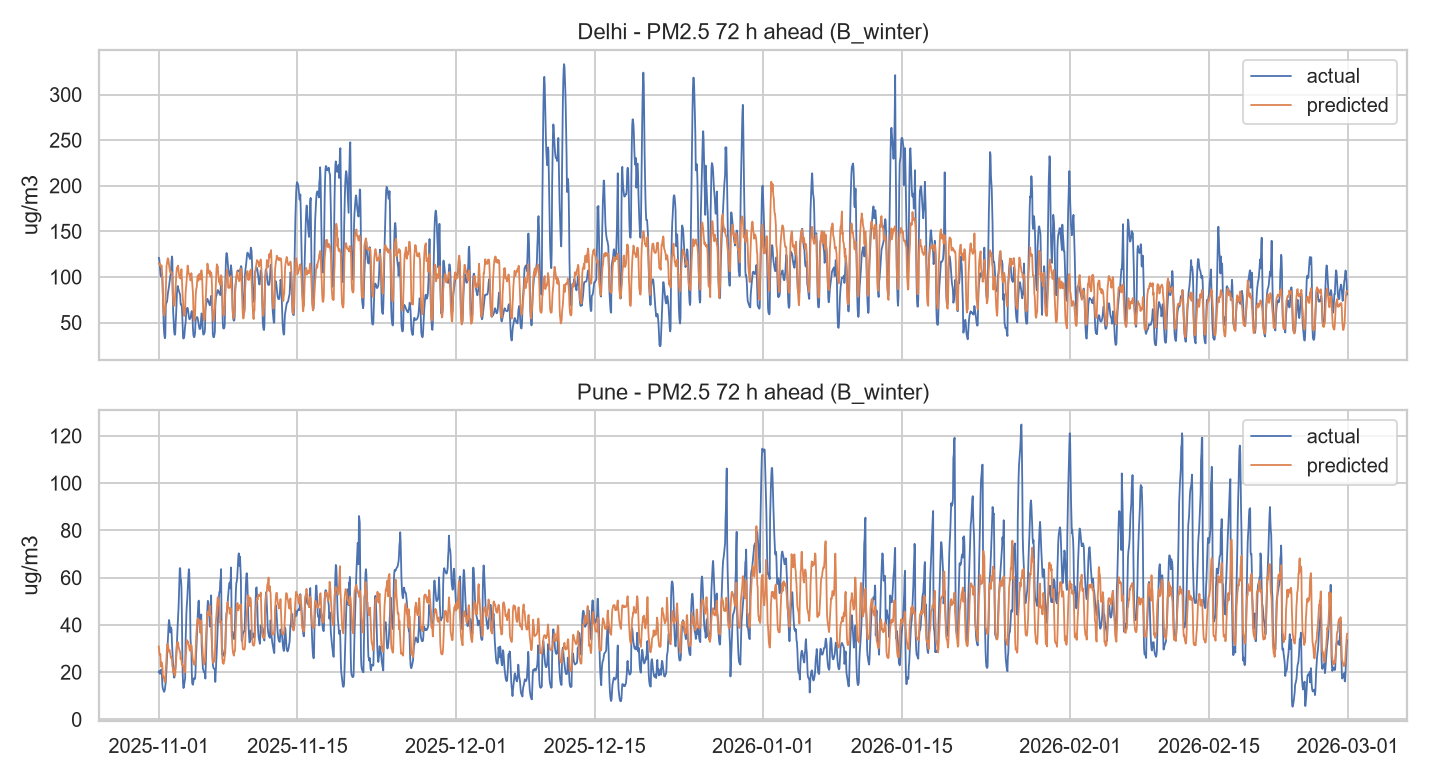

eval_alert_pr_curve.png


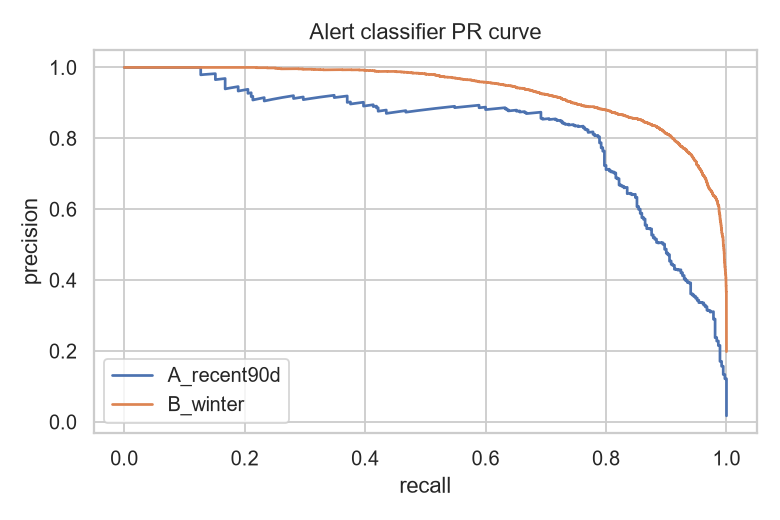

eval_by_city_A_recent90d.png


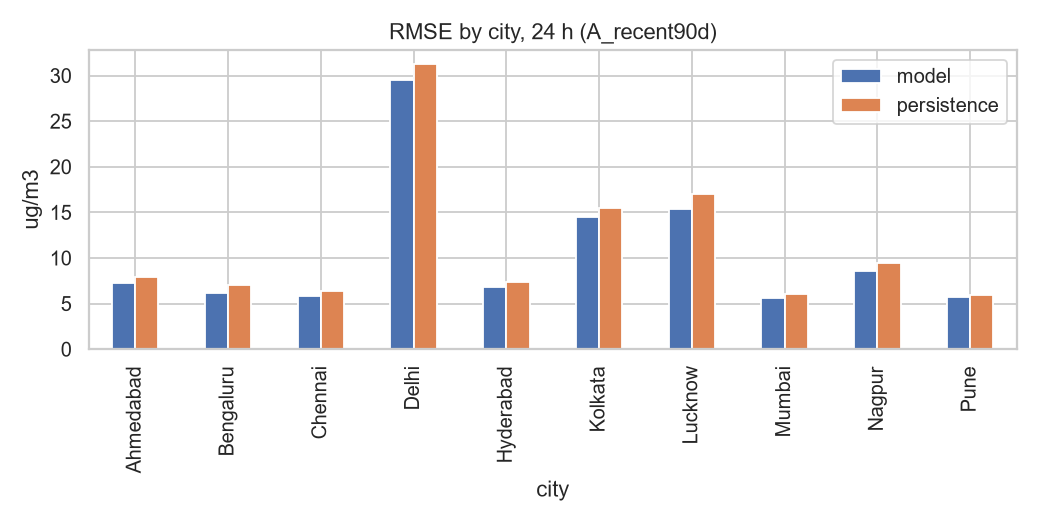

eval_by_city_B_winter.png


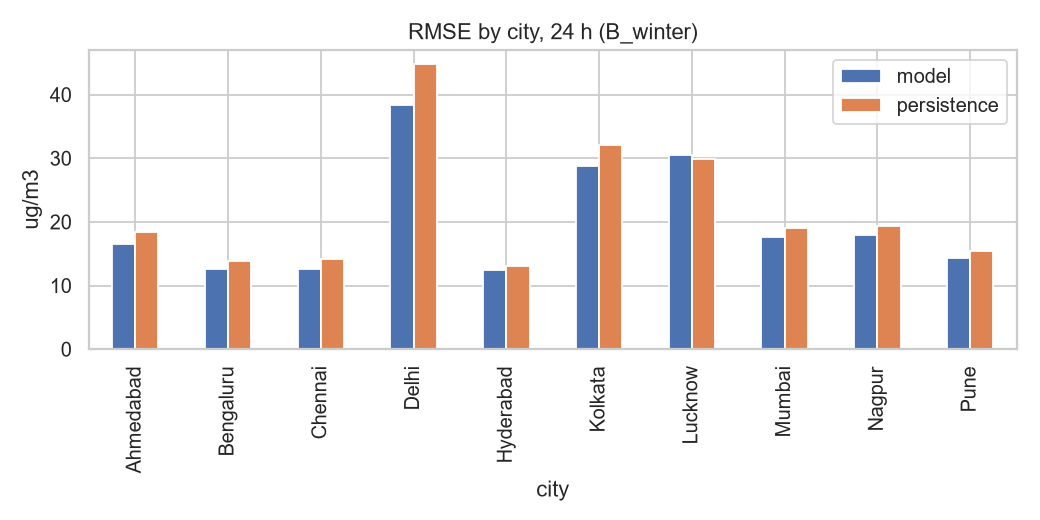

eval_category_confusion_A_recent90d.png


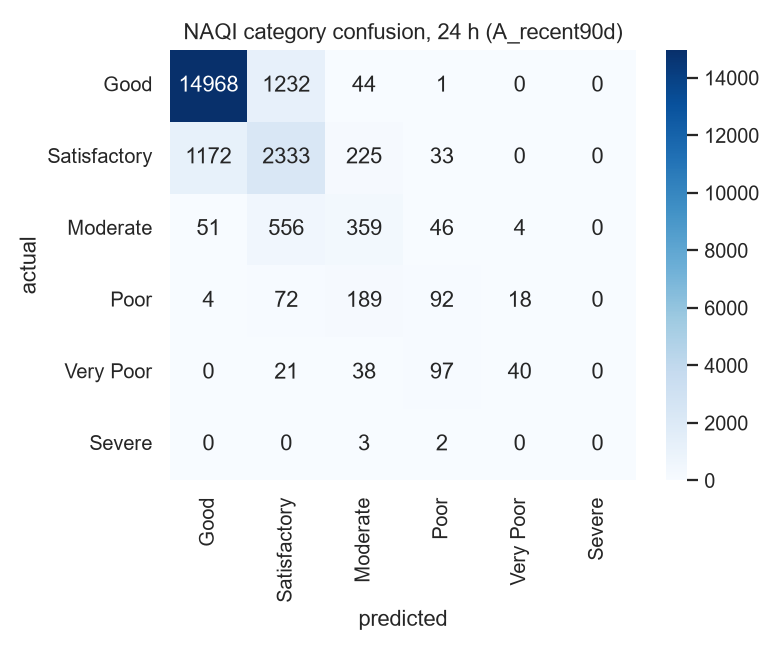

eval_category_confusion_B_winter.png


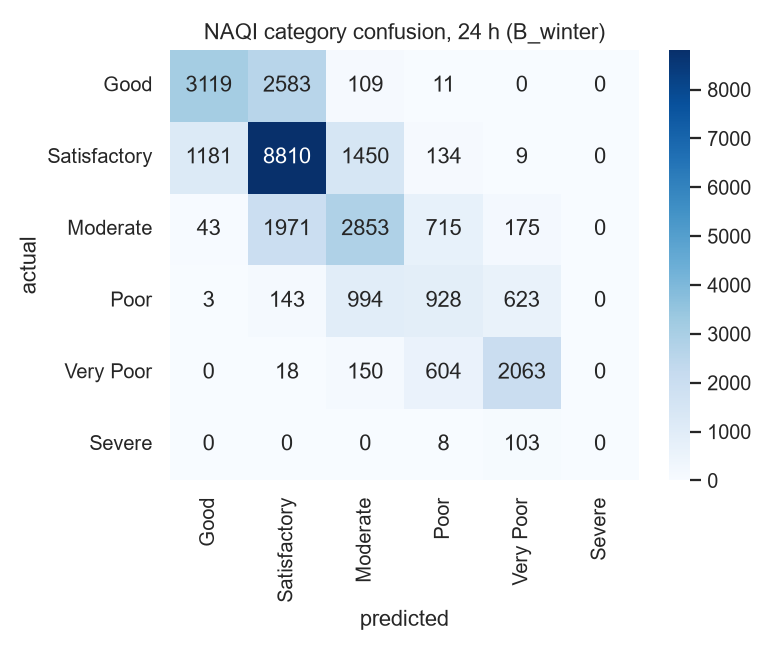

eval_error_vs_horizon.png


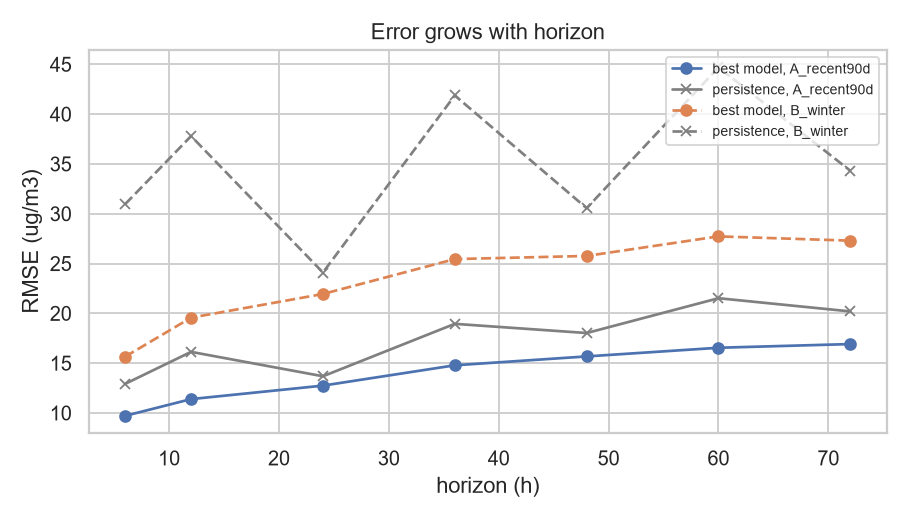

eval_residuals_24h_A_recent90d.png


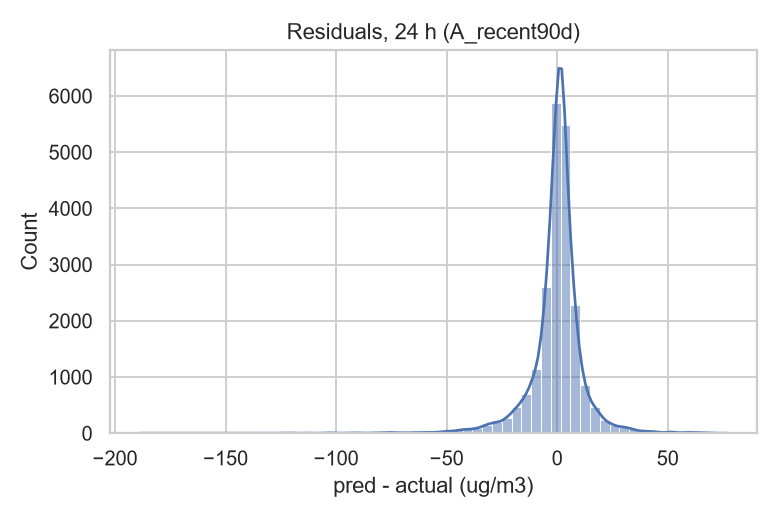

eval_residuals_24h_B_winter.png


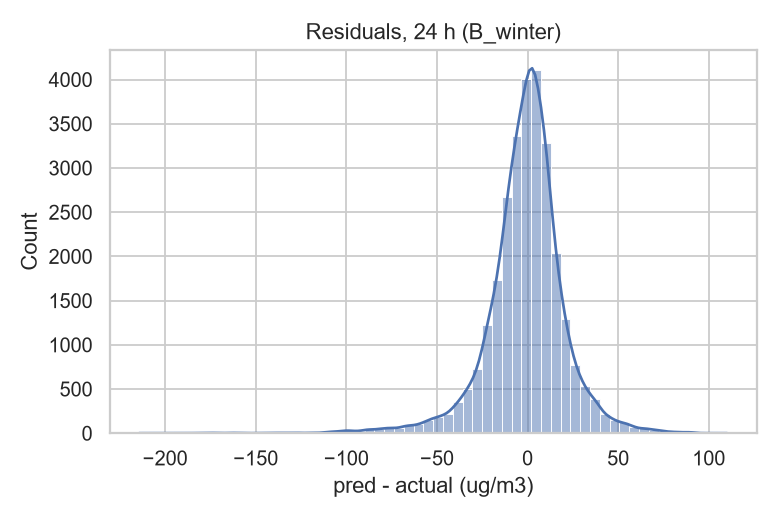

eval_residuals_72h_A_recent90d.png


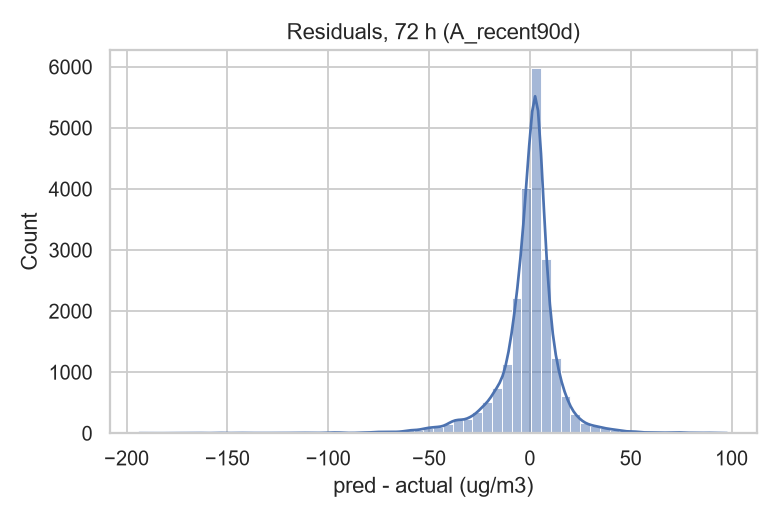

eval_residuals_72h_B_winter.png


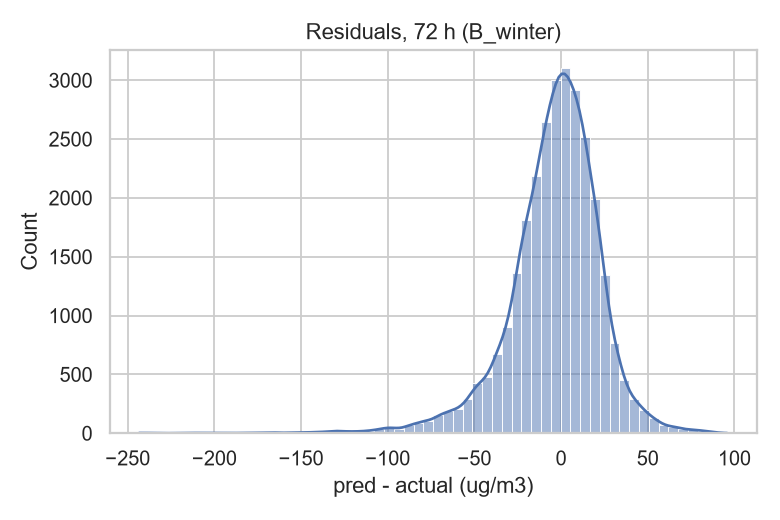

eval_rmse_heatmap_A_recent90d.png


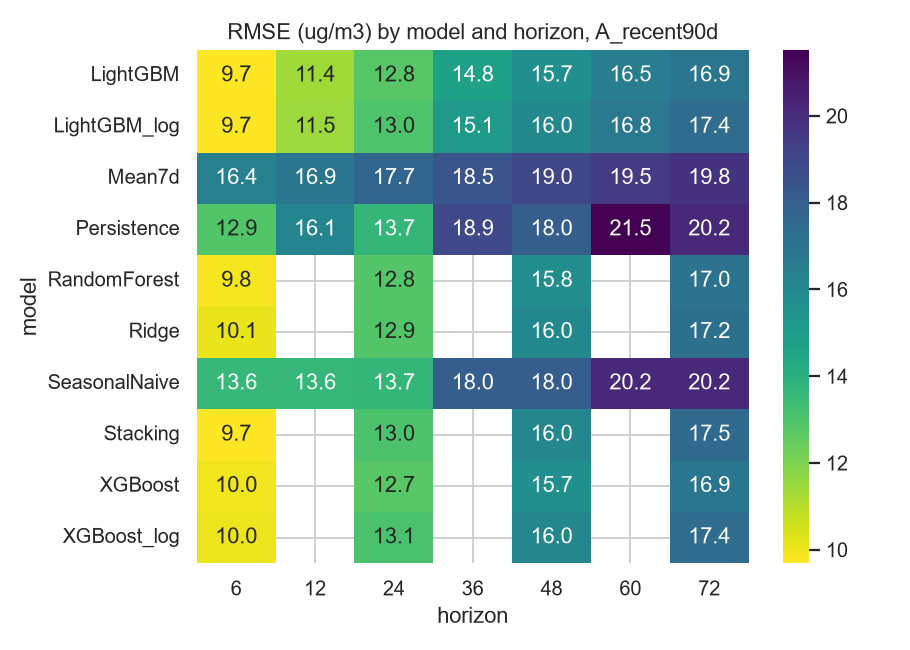

eval_rmse_heatmap_B_winter.png


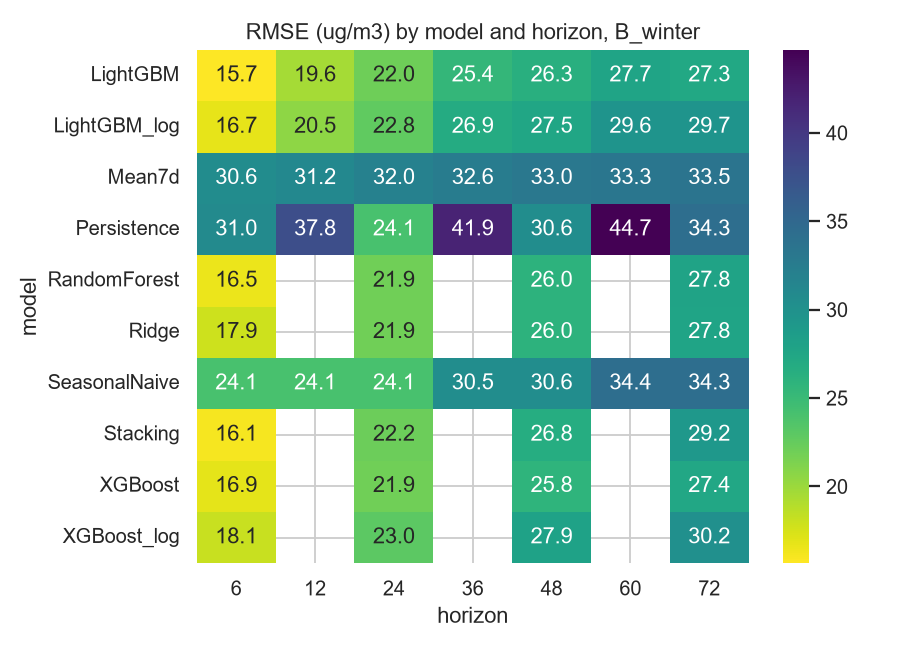

In [4]:
from IPython.display import Image, display
for f in sorted(FIG_DIR.glob('eval_*.png')): print(f.name); display(Image(str(f), width=700))

## Alert classifier

In [5]:
display(pd.read_csv(REPORT_DIR/'alert_metrics.csv').round(3)); display(pd.read_csv(REPORT_DIR/'category_accuracy.csv').round(3))

,test,threshold,precision,recall,f1,pr_auc,roc_auc,base_rate
0,A_recent90d,0.75,0.709,0.808,0.755,0.822,0.994,0.017
1,B_winter,0.75,0.789,0.919,0.849,0.935,0.982,0.198


,test,horizon,exact_category,within_one
0,A_recent90d,24,0.824,0.987
1,B_winter,24,0.617,0.972


## SHAP

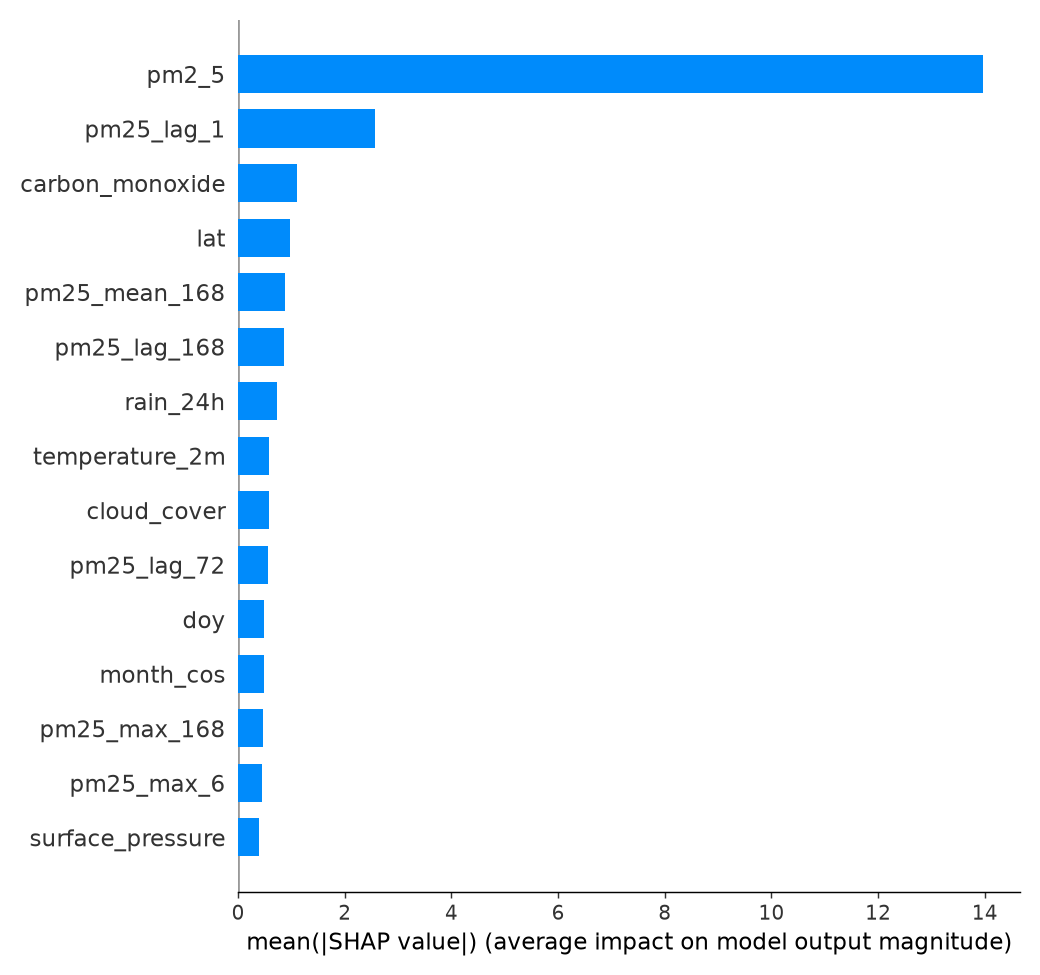

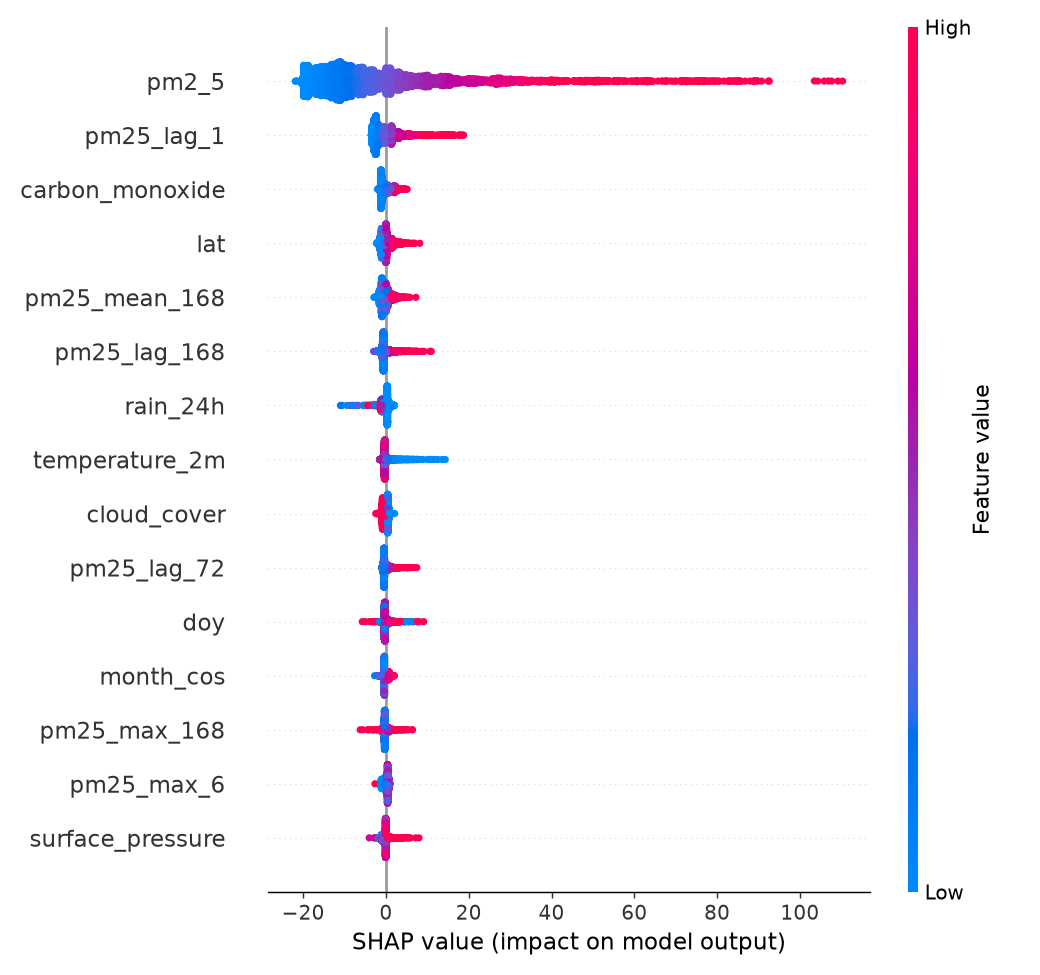

In [6]:
for n in ['shap_bar_24h.png','shap_beeswarm_24h.png']: display(Image(str(FIG_DIR/n), width=700))

## Conclusions
See `reports/final_report.md` for written conclusions with the measured numbers.